# Intelligent Customer Churn Prediction & Retention Optimization System
## Week 5: Comprehensive Data Science Project

This notebook synthesizes Weeks 1–4 and adds model interpretation, class-imbalance analysis, and strategic evidence preparation for the final report.


## 1. Imports and Data Loading
Load the IBM Telco Customer Churn dataset and prepare the working DataFrame.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_ind, chi2_contingency, f_oneway
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix,
    roc_curve, classification_report
)

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())


Shape: (7043, 21)
Missing values: 0


## 2. Data Cleaning
`TotalCharges` must be numeric. Blank values correspond to new customers with zero tenure in this dataset.


In [ ]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())


Missing values after cleaning: 0
Duplicates: 0


## 3. Exploratory Analysis


In [ ]:
churn_rate = pd.crosstab(
    df["Contract"], df["Churn"], normalize="index"
) * 100
print(churn_rate)

tenure_bins = [0, 12, 24, 48, 60, 72]
tenure_labels = ["0–12", "13–24", "25–48", "49–60", "61–72"]
df["TenureGroup"] = pd.cut(
    df["tenure"], bins=tenure_bins,
    labels=tenure_labels, include_lowest=True
)

tenure_churn = pd.crosstab(
    df["TenureGroup"], df["Churn"], normalize="index"
) * 100
print(tenure_churn)

payment_churn = pd.crosstab(
    df["PaymentMethod"], df["Churn"], normalize="index"
) * 100
print(payment_churn)


Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858
Churn               No        Yes
TenureGroup                      
0–12         52.561757  47.438243
13–24        71.289062  28.710938
25–48        79.611041  20.388959
49–60        85.576923  14.423077
61–72        93.390192   6.609808
Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


## 4. Statistical Validation


In [ ]:
stayed = df.loc[df["Churn"] == "No", "MonthlyCharges"]
churned = df.loc[df["Churn"] == "Yes", "MonthlyCharges"]

t_stat, t_p = ttest_ind(stayed, churned, equal_var=False)

contract_table = pd.crosstab(df["Contract"], df["Churn"])
chi2, chi_p, dof, expected = chi2_contingency(contract_table)

groups = [
    df.loc[df["Contract"] == c, "MonthlyCharges"]
    for c in ["Month-to-month", "One year", "Two year"]
]
f_stat, anova_p = f_oneway(*groups)

print("t-test:", t_stat, t_p)
print("Chi-square:", chi2, chi_p, "df =", dof)
print("ANOVA:", f_stat, anova_p)


t-test: -18.407526676414673 8.59244933154705e-73
Chi-square: 1184.5965720837926 5.863038300673391e-258 df = 2
ANOVA: 20.828045474730267 9.575270975935273e-10


## 5. Machine-Learning Preparation


In [ ]:
ml_df = df.copy()

ml_df["Churn"] = ml_df["Churn"].map({"No": 0, "Yes": 1})
ml_df = ml_df.drop("customerID", axis=1)

ml_df = pd.get_dummies(ml_df, drop_first=True)

X = ml_df.drop("Churn", axis=1)
y = ml_df["Churn"]

print("X shape:", X.shape)
print("y distribution:")
print(y.value_counts())


X shape: (7043, 34)
y distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [ ]:
## 6. Train-Test Split and Scaling


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(X_train.shape, X_test.shape)


(5634, 34) (1409, 34)


## 7. Logistic Regression


In [ ]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)
print("ROC-AUC:", roc_auc)


Accuracy: 0.7984386089425124
Precision: 0.65
Recall: 0.5213903743315508
F1: 0.5786350148367952
ROC-AUC: 0.8422873233614921


## 8. Confusion Matrix and ROC Curve


Confusion matrix:
 [[930 105]
 [179 195]]


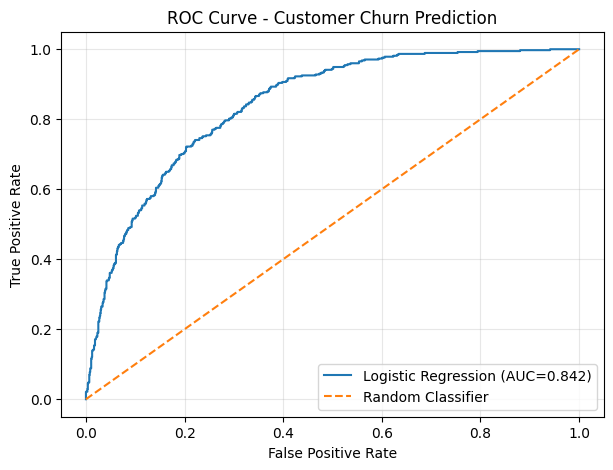

In [ ]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={roc_auc:.3f})")
plt.plot([0,1], [0,1], "--", label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn Prediction")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 9. Class Imbalance Analysis


Stayed (0): 5174 (73.46%)
Churned (1): 1869 (26.54%)


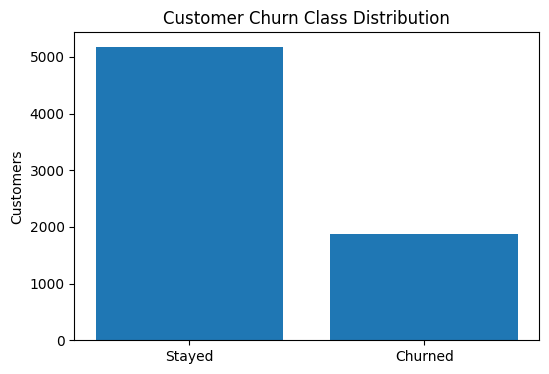

In [ ]:
class_counts = y.value_counts().sort_index()
class_percent = y.value_counts(normalize=True).sort_index() * 100

print("Stayed (0):", class_counts[0], f"({class_percent[0]:.2f}%)")
print("Churned (1):", class_counts[1], f"({class_percent[1]:.2f}%)")

plt.figure(figsize=(6,4))
plt.bar(["Stayed", "Churned"], [class_counts[0], class_counts[1]])
plt.ylabel("Customers")
plt.title("Customer Churn Class Distribution")
plt.show()


## 10. Feature Importance / Coefficient Analysis
This cell directly addresses the Week 4 evaluator feedback. Because the features were standardized, coefficient magnitude can be compared as a model-specific importance signal. Positive coefficients are associated with higher predicted churn probability; negative coefficients with lower predicted churn probability.


                           Feature  Coefficient  Absolute_Coefficient
1                           tenure    -1.201347              1.201347
2                   MonthlyCharges    -0.850921              0.850921
10     InternetService_Fiber optic     0.789231              0.789231
25               Contract_Two year    -0.645007              0.645007
33               TenureGroup_61–72     0.298778              0.298778
24               Contract_One year    -0.293669              0.293669
21                 StreamingTV_Yes     0.270331              0.270331
23             StreamingMovies_Yes     0.269212              0.269212
9                MultipleLines_Yes     0.239350              0.239350
32               TenureGroup_49–60     0.191325              0.191325
26            PaperlessBilling_Yes     0.187046              0.187046
28  PaymentMethod_Electronic check     0.178417              0.178417
3                     TotalCharges     0.171237              0.171237
13              Onli

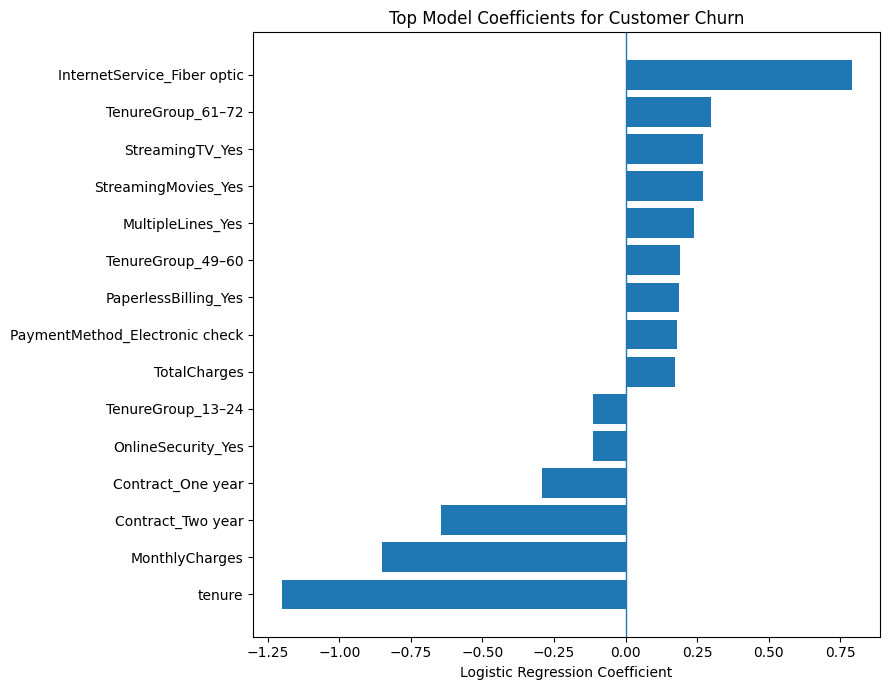

In [ ]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0]
})

feature_importance["Absolute_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

print(feature_importance.head(15))

top = feature_importance.head(15).sort_values("Coefficient")

plt.figure(figsize=(9,7))
plt.barh(top["Feature"], top["Coefficient"])
plt.axvline(0, linewidth=1)
plt.xlabel("Logistic Regression Coefficient")
plt.title("Top Model Coefficients for Customer Churn")
plt.tight_layout()
plt.show()


## 11. Strategic Evidence
Use the model output together with EDA and statistical evidence. Do not treat any single variable as proof of causation.


In [ ]:
print("Observed churn rate by contract:")
print(pd.crosstab(df["Contract"], df["Churn"], normalize="index")["Yes"] * 100)

print("\nObserved churn rate by payment method:")
print(pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index")["Yes"] * 100)

print("\nMean MonthlyCharges:")
print(df.groupby("Churn")["MonthlyCharges"].mean())

print("\nMean tenure:")
print(df.groupby("Churn")["tenure"].mean())


Observed churn rate by contract:
Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Yes, dtype: float64

Observed churn rate by payment method:
PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: Yes, dtype: float64

Mean MonthlyCharges:
Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

Mean tenure:
Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


## 12. Final Interpretation Checklist
Before submitting the Week 5 report, confirm that:
- The executive summary is present.
- All four previous weeks are integrated.
- Class imbalance is discussed.
- Feature coefficients are generated and interpreted.
- Confusion matrix and ROC curve are included.
- Recommendations are directly linked to evidence.
- Limitations and future improvements are explicit.
- The DOCX and notebook are consistent with the executed results.
